In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10
co2_data = pd.read_csv('owid-co2-data.csv')
print(co2_data.head())

        Entity Code  Year  Annual CO₂ emissions
0  Afghanistan  AFG  1949               14656.0
1  Afghanistan  AFG  1950               84272.0
2  Afghanistan  AFG  1951               91600.0
3  Afghanistan  AFG  1952               91600.0
4  Afghanistan  AFG  1953              106256.0


In [3]:
print(f"\nРазмерность исходного DataFrame: {co2_data.shape}")
print(f"Количество строк: {co2_data.shape[0]:,}")
print(f"Количество столбцов: {co2_data.shape[1]}")


Размерность исходного DataFrame: (29384, 4)
Количество строк: 29,384
Количество столбцов: 4


In [4]:
print(co2_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29384 entries, 0 to 29383
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Entity                29384 non-null  object 
 1   Code                  23714 non-null  object 
 2   Year                  29384 non-null  int64  
 3   Annual CO₂ emissions  29384 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 918.4+ KB
None


# Проверка пропущенных значений

In [5]:
print("\nПропущенные значения по столбцам:")
missing_values = co2_data.isnull().sum()
for col, missing in missing_values.items():
    if missing > 0:
        print(f"  {col}: {missing:,} ({missing/len(co2_data)*100:.1f}%)")


Пропущенные значения по столбцам:
  Code: 5,670 (19.3%)


# Описательная статистика по ключевым показателям

In [6]:
print("\nОписательная статистика по ключевым показателям:")
print(co2_data[['Year', 'Annual CO₂ emissions']].describe())


Описательная статистика по ключевым показателям:
               Year  Annual CO₂ emissions
count  29384.000000          2.938400e+04
mean    1948.359243          4.202270e+08
std       59.148142          1.972092e+09
min     1750.000000          0.000000e+00
25%     1913.000000          3.810560e+05
50%     1963.000000          5.080756e+06
75%     1995.000000          5.365634e+07
max     2024.000000          3.859858e+10


In [7]:
co2_clean = co2_data.dropna(subset=['Code']).copy()
print(f"После удаления строк без кода: {co2_clean.shape[0]:,} строк")

После удаления строк без кода: 23,714 строк


In [8]:
co2_clean = co2_clean[co2_clean['Entity'] != 'World']
print(f"После удаления 'World': {co2_clean.shape[0]:,} строк")

После удаления 'World': 23,439 строк


In [9]:
print(f"\nИтоговая размерность: {co2_clean.shape}")


Итоговая размерность: (23439, 4)


# Шаг 4. Ответы на вопросы

 # Топ-10 стран

# Вопрос 1: Страна с наибольшими общими выбросами CO2

In [10]:
country_emissions = co2_clean.groupby('Entity')['Annual CO₂ emissions'].sum().sort_values(ascending=False)


top_country = country_emissions.index[0]
top_emissions = country_emissions.iloc[0]

print(f"Страна-лидер: {top_country}")
print(f"Общие выбросы: {top_emissions:,.0f} тонн")
print(f"Это составляет {top_emissions/1e9:.2f} миллиардов тонн")


print("\nТоп-10 стран по общим выбросам:")
for i, (country, emissions) in enumerate(country_emissions.head(10).items(), 1):
    print(f"{i:2d}. {country:25s} - {emissions:15,.0f} тонн ({emissions/1e9:8.2f} млрд)")

Страна-лидер: United States
Общие выбросы: 434,866,568,350 тонн
Это составляет 434.87 миллиардов тонн

Топ-10 стран по общим выбросам:
 1. United States             - 434,866,568,350 тонн (  434.87 млрд)
 2. China                     - 285,087,038,068 тонн (  285.09 млрд)
 3. Russia                    - 122,808,231,943 тонн (  122.81 млрд)
 4. Germany                   -  95,135,675,962 тонн (   95.14 млрд)
 5. United Kingdom            -  80,079,446,353 тонн (   80.08 млрд)
 6. Japan                     -  69,612,279,266 тонн (   69.61 млрд)
 7. India                     -  66,072,530,817 тонн (   66.07 млрд)
 8. France                    -  40,047,568,498 тонн (   40.05 млрд)
 9. Canada                    -  35,644,130,844 тонн (   35.64 млрд)
10. Ukraine                   -  31,236,494,637 тонн (   31.24 млрд)


# Вопрос 2: Выбросы по десятилетиям

# Создание столбца с десятилетиями

In [11]:
co2_clean['Decade'] = (co2_clean['Year'] // 10) * 10

# Суммарные выбросы по десятилетиям

In [12]:
decade_emissions = co2_clean.groupby('Decade')['Annual CO₂ emissions'].sum()

In [13]:
for decade, emissions in decade_emissions.items():
    print(f"{decade}-е: {emissions:20,.0f} тонн ({emissions/1e9:10.2f} млрд тонн)")

1750-е:           97,914,934 тонн (      0.10 млрд тонн)
1760-е:          115,722,073 тонн (      0.12 млрд тонн)
1770-е:          142,642,063 тонн (      0.14 млрд тонн)
1780-е:          177,649,313 тонн (      0.18 млрд тонн)
1790-е:          225,193,814 тонн (      0.23 млрд тонн)
1800-е:          338,391,250 тонн (      0.34 млрд тонн)
1810-е:          444,598,243 тонн (      0.44 млрд тонн)
1820-е:          591,596,306 тонн (      0.59 млрд тонн)
1830-е:          952,335,011 тонн (      0.95 млрд тонн)
1840-е:        1,486,962,157 тонн (      1.49 млрд тонн)
1850-е:        2,483,303,860 тонн (      2.48 млрд тонн)
1860-е:        4,210,496,819 тонн (      4.21 млрд тонн)
1870-е:        6,581,098,084 тонн (      6.58 млрд тонн)
1880-е:       10,230,381,820 тонн (     10.23 млрд тонн)
1890-е:       15,064,007,612 тонн (     15.06 млрд тонн)
1900-е:       24,212,319,213 тонн (     24.21 млрд тонн)
1910-е:       32,775,964,035 тонн (     32.78 млрд тонн)
1920-е:       37,061,114,245 то

In [14]:
print("\nДинамика роста:")
decade_growth = decade_emissions.pct_change() * 100
for decade, growth in decade_growth.items():
    if not np.isnan(growth):
        print(f"{decade}-е: {growth:+.1f}% к предыдущему десятилетию")


Динамика роста:
1760-е: +18.2% к предыдущему десятилетию
1770-е: +23.3% к предыдущему десятилетию
1780-е: +24.5% к предыдущему десятилетию
1790-е: +26.8% к предыдущему десятилетию
1800-е: +50.3% к предыдущему десятилетию
1810-е: +31.4% к предыдущему десятилетию
1820-е: +33.1% к предыдущему десятилетию
1830-е: +61.0% к предыдущему десятилетию
1840-е: +56.1% к предыдущему десятилетию
1850-е: +67.0% к предыдущему десятилетию
1860-е: +69.6% к предыдущему десятилетию
1870-е: +56.3% к предыдущему десятилетию
1880-е: +55.5% к предыдущему десятилетию
1890-е: +47.2% к предыдущему десятилетию
1900-е: +60.7% к предыдущему десятилетию
1910-е: +35.4% к предыдущему десятилетию
1920-е: +13.1% к предыдущему десятилетию
1930-е: +5.1% к предыдущему десятилетию
1940-е: +27.9% к предыдущему десятилетию
1950-е: +43.0% к предыдущему десятилетию
1960-е: +52.3% к предыдущему десятилетию
1970-е: +54.7% к предыдущему десятилетию
1980-е: +17.3% к предыдущему десятилетию
1990-е: +16.4% к предыдущему десятилетию


# Вопрос 3: Доминирующая континентальная группа

In [15]:
continent_mapping = {
    'China': 'Asia', 'India': 'Asia', 'Japan': 'Asia', 'South Korea': 'Asia',
    'Indonesia': 'Asia', 'Saudi Arabia': 'Asia', 'Iran': 'Asia', 'Thailand': 'Asia',
    'Pakistan': 'Asia', 'Malaysia': 'Asia', 'Vietnam': 'Asia', 'Philippines': 'Asia',
    'Bangladesh': 'Asia', 'Iraq': 'Asia', 'Kazakhstan': 'Asia', 'United Arab Emirates': 'Asia',
    'Taiwan': 'Asia', 'Singapore': 'Asia', 'Israel': 'Asia', 'Hong Kong': 'Asia',
    
    'Russia': 'Europe', 'Germany': 'Europe', 'United Kingdom': 'Europe', 'France': 'Europe',
    'Italy': 'Europe', 'Poland': 'Europe', 'Spain': 'Europe', 'Ukraine': 'Europe',
    'Netherlands': 'Europe', 'Belgium': 'Europe', 'Czech Republic': 'Europe', 'Romania': 'Europe',
    'Greece': 'Europe', 'Austria': 'Europe', 'Sweden': 'Europe', 'Finland': 'Europe',
    'Portugal': 'Europe', 'Denmark': 'Europe', 'Norway': 'Europe', 'Switzerland': 'Europe',
    'Ireland': 'Europe', 'Bulgaria': 'Europe', 'Hungary': 'Europe', 'Serbia': 'Europe',
    

    'United States': 'North America', 'Canada': 'North America', 'Mexico': 'North America',
    

    'Brazil': 'South America', 'Argentina': 'South America', 'Venezuela': 'South America',
    'Colombia': 'South America', 'Chile': 'South America', 'Peru': 'South America',

    'South Africa': 'Africa', 'Egypt': 'Africa', 'Algeria': 'Africa', 'Nigeria': 'Africa',
    'Morocco': 'Africa', 'Libya': 'Africa', 'Kenya': 'Africa', 'Ethiopia': 'Africa',

    'Australia': 'Oceania', 'New Zealand': 'Oceania'
}

In [16]:
co2_clean['Continent'] = co2_clean['Entity'].map(continent_mapping)

co2_with_continent = co2_clean[co2_clean['Continent'].notna()].copy()

latest_year = co2_with_continent['Year'].max()
latest_data = co2_with_continent[co2_with_continent['Year'] == latest_year]

continent_emissions = latest_data.groupby('Continent')['Annual CO₂ emissions'].sum().sort_values(ascending=False)

print(f"\nАнализ выбросов по континентам за {int(latest_year)} год:")
print(f"(на основе {len(continent_mapping)} крупнейших стран-эмитентов)\n")

total_mapped = continent_emissions.sum()
for continent, emissions in continent_emissions.items():
    percentage = (emissions / total_mapped) * 100
    print(f"  {continent:20s} - {emissions:15,.0f} тонн ({emissions/1e9:6.2f} млрд, {percentage:5.1f}%)")

dominant_continent = continent_emissions.index[0]
dominant_emissions = continent_emissions.iloc[0]

print(f"\n Доминирующий континент: {dominant_continent}")
print(f" Выбросы: {dominant_emissions:,.0f} тонн ({dominant_emissions/1e9:.2f} млрд тонн)")
print(f" Доля от анализируемых стран: {(dominant_emissions/total_mapped)*100:.1f}%")


print("Историческая динамика выбросов по континентам:")


continent_total_emissions = co2_with_continent.groupby('Continent')['Annual CO₂ emissions'].sum().sort_values(ascending=False)

print("\nСуммарные выбросы за весь период (1750-2017):")
for continent, emissions in continent_total_emissions.items():
    print(f"  {continent:20s} - {emissions:15,.0f} тонн ({emissions/1e9:8.2f} млрд)")



Анализ выбросов по континентам за 2024 год:
(на основе 63 крупнейших стран-эмитентов)

  Asia                 -  21,861,812,964 тонн ( 21.86 млрд,  62.5%)
  North America        -   5,898,447,750 тонн (  5.90 млрд,  16.9%)
  Europe               -   4,594,059,830 тонн (  4.59 млрд,  13.1%)
  Africa               -   1,205,610,680 тонн (  1.21 млрд,   3.4%)
  South America        -   1,011,744,812 тонн (  1.01 млрд,   2.9%)
  Oceania              -     419,211,812 тонн (  0.42 млрд,   1.2%)

 Доминирующий континент: Asia
 Выбросы: 21,861,812,964 тонн (21.86 млрд тонн)
 Доля от анализируемых стран: 62.5%
Историческая динамика выбросов по континентам:

Суммарные выбросы за весь период (1750-2017):
  Asia                 - 575,284,334,231 тонн (  575.28 млрд)
  Europe               - 519,964,972,523 тонн (  519.96 млрд)
  North America        - 492,526,550,877 тонн (  492.53 млрд)
  Africa               -  45,872,938,829 тонн (   45.87 млрд)
  South America        -  44,525,438,787 тонн (

# График 1: Выбросы по десятилетиям

Сохранен график: co2_by_decade.png


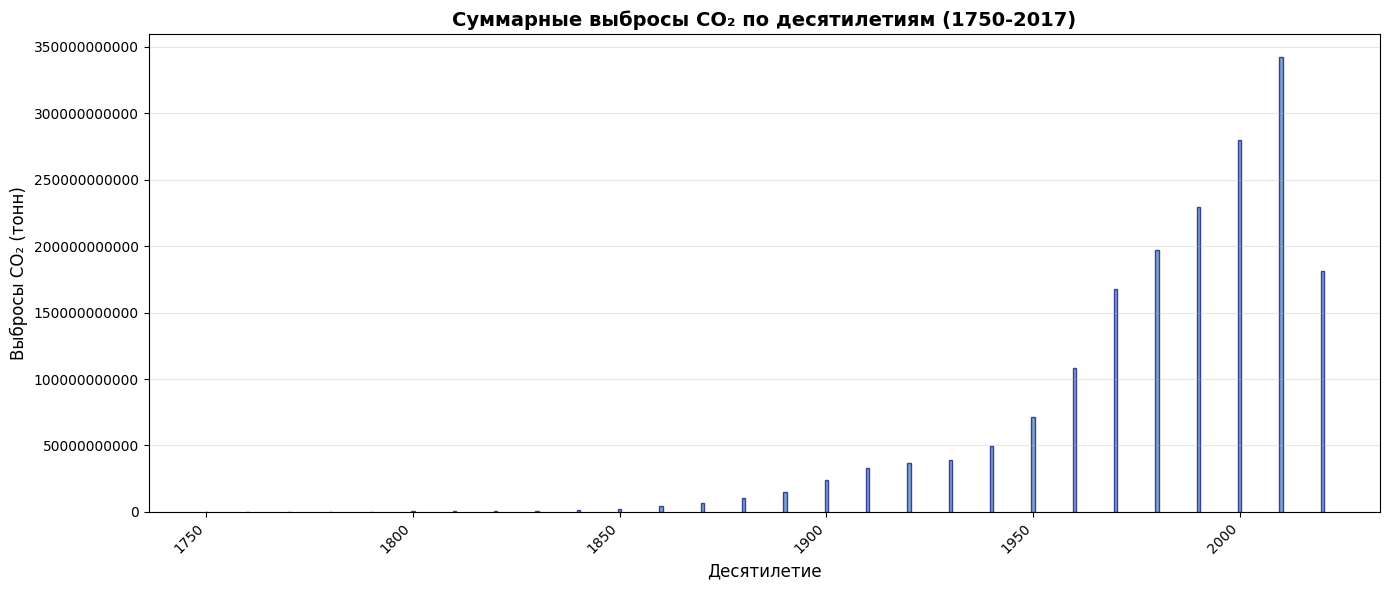

In [17]:
plt.figure(figsize=(14, 6))
bars = plt.bar(decade_emissions.index, decade_emissions.values, color='steelblue', edgecolor='navy', alpha=0.7)
plt.title('Суммарные выбросы CO₂ по десятилетиям (1750-2017)', fontsize=14, fontweight='bold')
plt.xlabel('Десятилетие', fontsize=12)
plt.ylabel('Выбросы CO₂ (тонн)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.savefig('co2_by_decade.png', dpi=300, bbox_inches='tight')
print("Сохранен график: co2_by_decade.png")
plt.show()


# График 2: Топ-10 стран

Сохранен график: top10_countries_co2.png


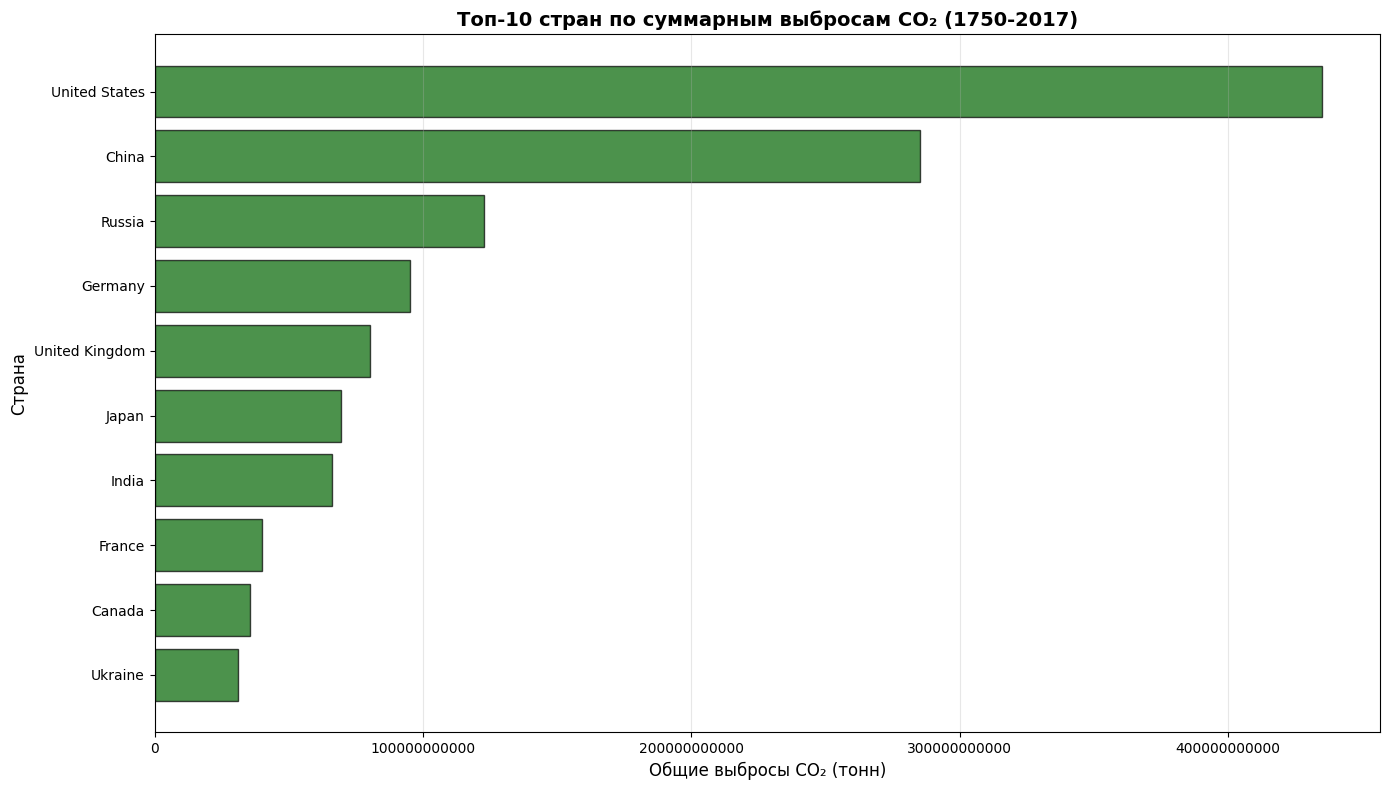

In [18]:
plt.figure(figsize=(14, 8))
top10 = country_emissions.head(10)
bars = plt.barh(range(len(top10)), top10.values, color='darkgreen', edgecolor='black', alpha=0.7)
plt.yticks(range(len(top10)), top10.index)
plt.xlabel('Общие выбросы CO₂ (тонн)', fontsize=12)
plt.ylabel('Страна', fontsize=12)
plt.title('Топ-10 стран по суммарным выбросам CO₂ (1750-2017)', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.savefig('top10_countries_co2.png', dpi=300, bbox_inches='tight')
print("Сохранен график: top10_countries_co2.png")
plt.show()

# График 3: Динамика выбросов во времени (топ-5 стран)

 Сохранен график: top5_countries_timeline.png


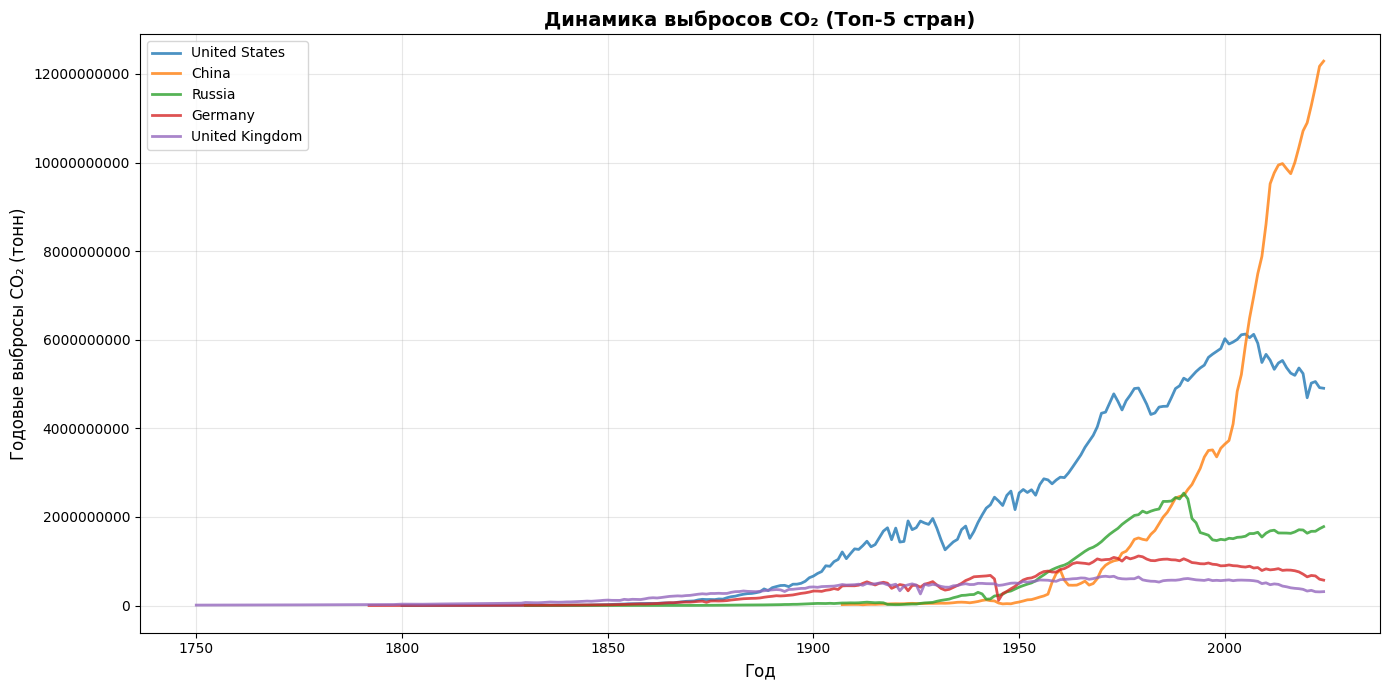

In [19]:
plt.figure(figsize=(14, 7))
top5_countries = country_emissions.head(5).index

for country in top5_countries:
    country_data = co2_clean[co2_clean['Entity'] == country].sort_values('Year')
    plt.plot(country_data['Year'], country_data['Annual CO₂ emissions'], 
             marker='', linewidth=2, label=country, alpha=0.8)

plt.title('Динамика выбросов CO₂ (Топ-5 стран)', fontsize=14, fontweight='bold')
plt.xlabel('Год', fontsize=12)
plt.ylabel('Годовые выбросы CO₂ (тонн)', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.savefig('top5_countries_timeline.png', dpi=300, bbox_inches='tight')
print(" Сохранен график: top5_countries_timeline.png")
plt.show()

Сохранен график: continents_co2.png


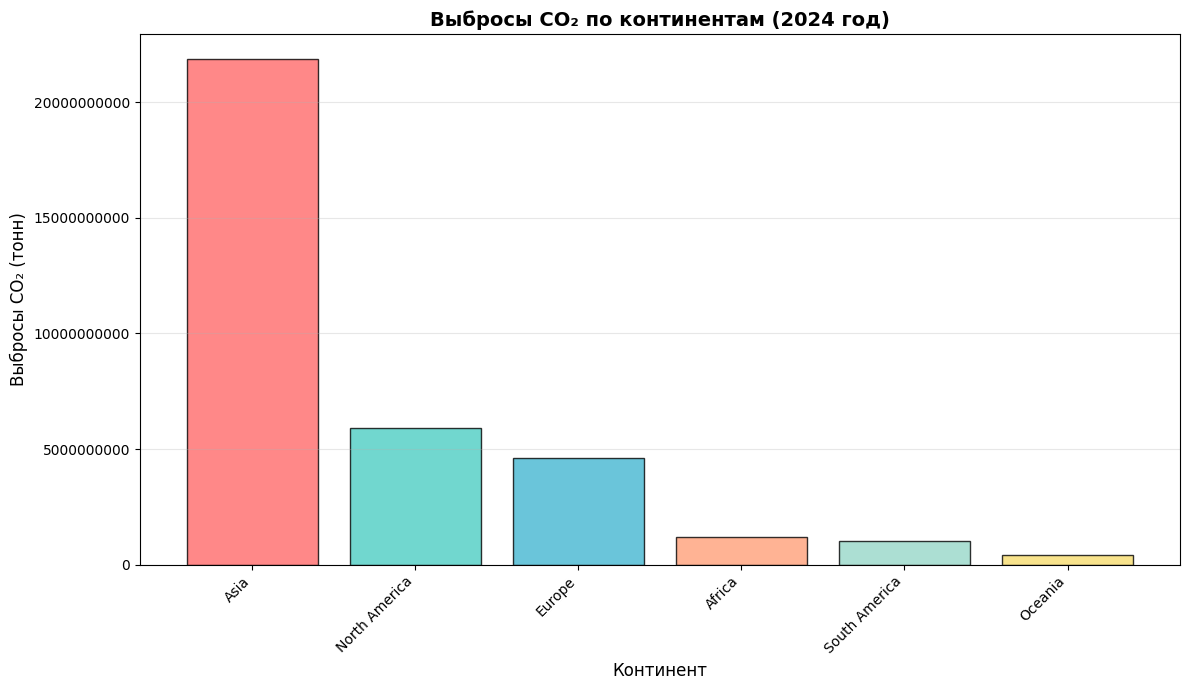

In [20]:
plt.figure(figsize=(12, 7))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8', '#F7DC6F']
bars = plt.bar(continent_emissions.index, continent_emissions.values, color=colors, edgecolor='black', alpha=0.8)
plt.title(f'Выбросы CO₂ по континентам ({int(latest_year)} год)', fontsize=14, fontweight='bold')
plt.xlabel('Континент', fontsize=12)
plt.ylabel('Выбросы CO₂ (тонн)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.savefig('continents_co2.png', dpi=300, bbox_inches='tight')
print("Сохранен график: continents_co2.png")
plt.show()

In [21]:

print("ЛАБОРАТОРНАЯ РАБОТА №8 УСПЕШНО ВЫПОЛНЕНА!")

print("\nСозданные файлы:")
print("  - co2_by_decade.png")
print("  - top10_countries_co2.png")
print("  - top5_countries_timeline.png")
print("  - continents_co2.png")

ЛАБОРАТОРНАЯ РАБОТА №8 УСПЕШНО ВЫПОЛНЕНА!

Созданные файлы:
  - co2_by_decade.png
  - top10_countries_co2.png
  - top5_countries_timeline.png
  - continents_co2.png
